# Day 36 — Task Sheet_Time Series Fundamentals


## Part A — See what you have



## TASK 01 — Plot at three scales

Missing dates: 0
Missing values before handling:
sales       6
store_id    0
promo       0
temp_c      0
dtype: int64

Missing values after handling:
sales       0
store_id    0
promo       0
temp_c      0
dtype: int64


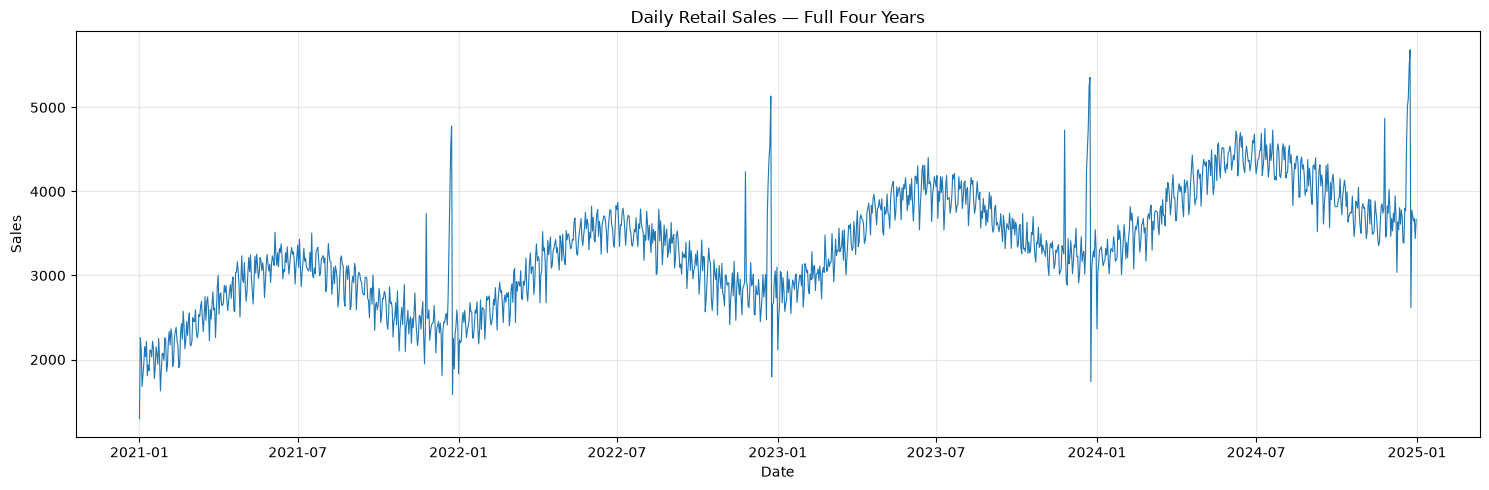

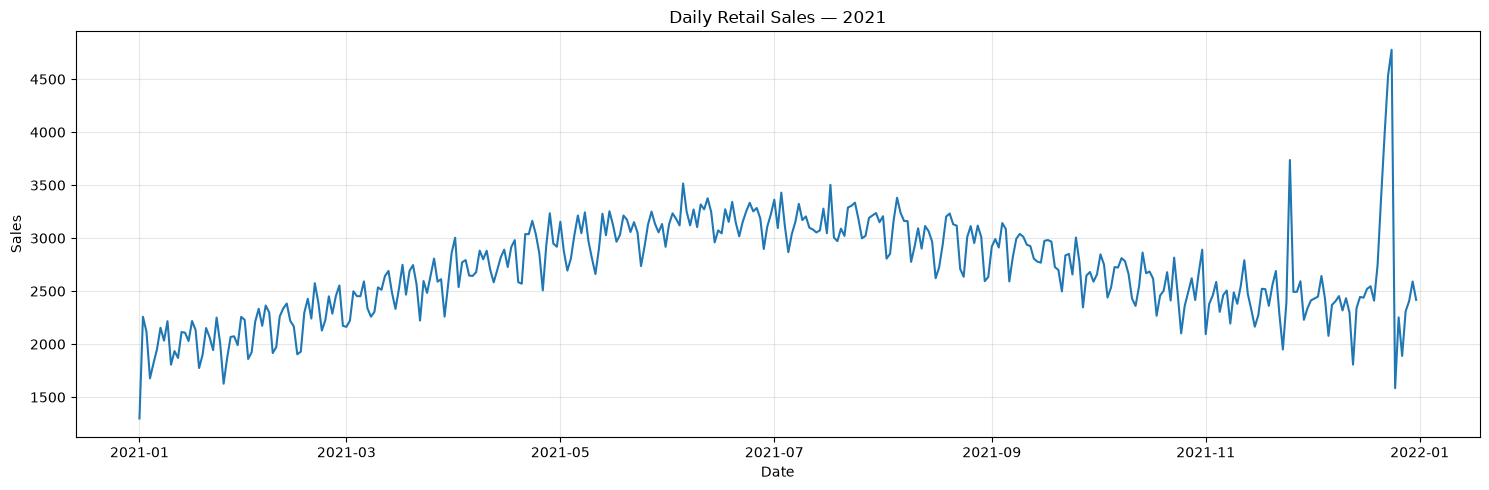

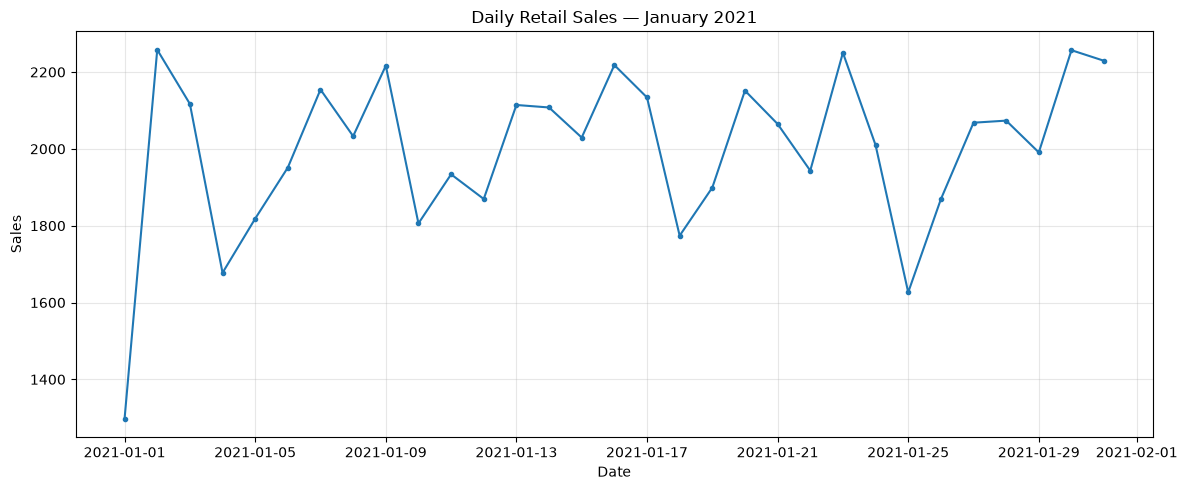

In [1]:
# Day 36 — Task 01: Time Series at Three Scales

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. Load the dataset and parse dates
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])

# Set date as the index and sort chronologically
df = df.set_index("date").sort_index()

# Check that the dataset has unique dates
assert df.index.is_unique, "Duplicate dates found!"

# 3. Check for missing dates
complete_dates = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

missing_dates = complete_dates.difference(df.index)

print("Missing dates:", len(missing_dates))
print("Missing values before handling:")
print(df.isnull().sum())

# Add missing dates to the dataset
df = df.reindex(complete_dates)
df.index.name = "date"

# 4. Handle missing sales values
# Time-based interpolation estimates missing sales using
# surrounding dates, preserving chronological order.
df["sales"] = df["sales"].interpolate(
    method="time",
    limit_area="inside"
)

# Verify the data after handling missing values
print("\nMissing values after handling:")
print(df.isnull().sum())

# 5. Plot the full four years
plt.figure(figsize=(15, 5))

plt.plot(df.index, df["sales"], linewidth=0.8)

plt.title("Daily Retail Sales — Full Four Years")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Plot a single year: 2021
year_data = df.loc["2021"]

plt.figure(figsize=(15, 5))

plt.plot(year_data.index, year_data["sales"])

plt.title("Daily Retail Sales — 2021")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Plot a single month: January 2021
month_data = df.loc["2021-01"]

plt.figure(figsize=(12, 5))

plt.plot(
    month_data.index,
    month_data["sales"],
    marker="o",
    markersize=3
)

plt.title("Daily Retail Sales — January 2021")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Task 01 — Required Conclusion

The series contains 2 distinct cycles:

- Annual cycle: Visible in the full four-year plot.
- Weekly cycle: Visible in the single-month plot.

The single-year plot makes the repeating weekly fluctuations easier to see than the long-term trend.

A pattern invisible at the full-series scale becomes obvious when zooming into a single month.

## TASK 02 — Handle the gaps correctly

Dates with missing sales:
['2021-03-25', '2021-12-02', '2022-02-04', '2023-08-16', '2024-04-18', '2024-12-27']

Mean and standard deviation comparison:
                               Mean  Standard Deviation
Original (observed values)  3328.27              645.58
Overall Mean Fill           3328.27              644.25
Forward Fill                3327.79              645.82
Time Interpolation          3328.11              645.87


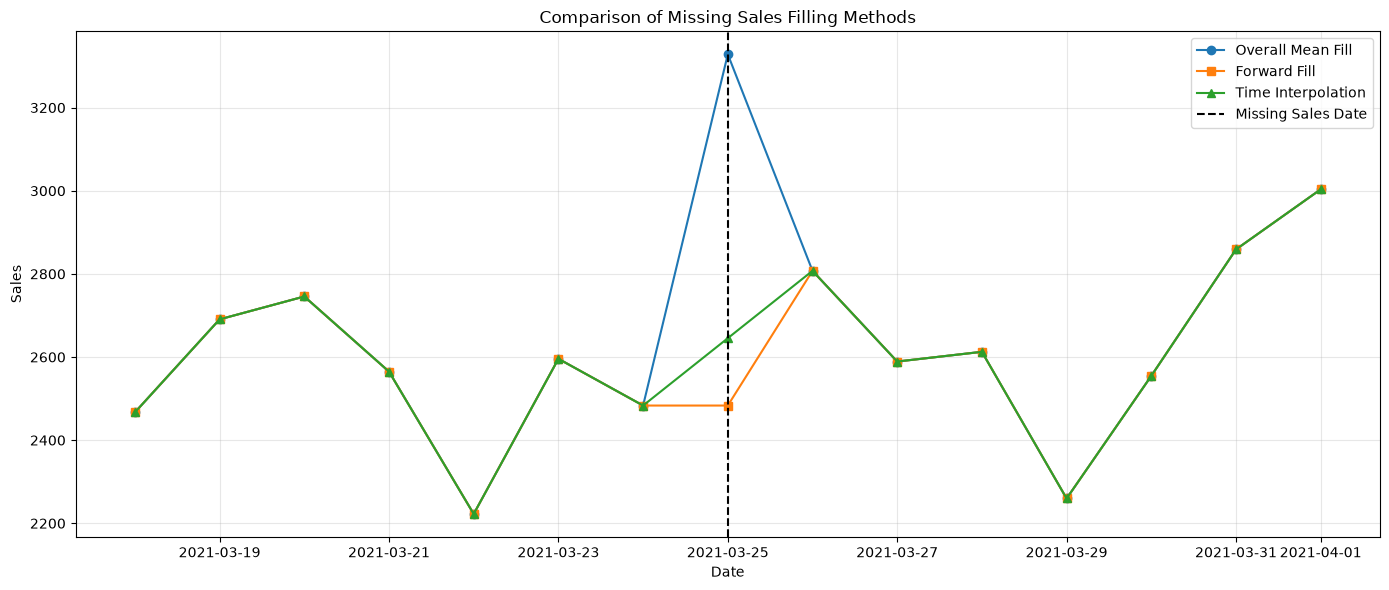

In [2]:
# Day 36 — Task 02: Handle Missing Sales Values

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load original data to preserve the missing sales values
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])
df = df.set_index("date").sort_index()

# Identify dates with missing sales
missing_dates = df.index[df["sales"].isna()]

print("Dates with missing sales:")
print(missing_dates.strftime("%Y-%m-%d").tolist())

# Keep the original sales series unchanged
sales = df["sales"].copy()

# Fill missing values using three different methods
sales_mean = sales.fillna(sales.mean())
sales_ffill = sales.ffill()
sales_interpolated = sales.interpolate(method="time")

# Compare mean and standard deviation
comparison = pd.DataFrame({
    "Mean": [
        sales.mean(),
        sales_mean.mean(),
        sales_ffill.mean(),
        sales_interpolated.mean()
    ],
    "Standard Deviation": [
        sales.std(),
        sales_mean.std(),
        sales_ffill.std(),
        sales_interpolated.std()
    ]
}, index=[
    "Original (observed values)",
    "Overall Mean Fill",
    "Forward Fill",
    "Time Interpolation"
])

print("\nMean and standard deviation comparison:")
print(comparison.round(2))

# Plot a two-week window around the first missing date
if len(missing_dates) > 0:

    gap_date = missing_dates[0]

    # Select seven days before and after the gap
    start_date = gap_date - pd.Timedelta(days=7)
    end_date = gap_date + pd.Timedelta(days=7)

    window = pd.DataFrame({
        "Original Sales": sales,
        "Overall Mean Fill": sales_mean,
        "Forward Fill": sales_ffill,
        "Time Interpolation": sales_interpolated
    }).loc[start_date:end_date]

    # Plot all three filling methods
    plt.figure(figsize=(14, 6))

    plt.plot(
        window.index, window["Overall Mean Fill"],
        marker="o", label="Overall Mean Fill"
    )

    plt.plot(
        window.index, window["Forward Fill"],
        marker="s", label="Forward Fill"
    )

    plt.plot(
        window.index, window["Time Interpolation"],
        marker="^", label="Time Interpolation"
    )

    # Mark the missing date
    plt.axvline(
        gap_date,
        color="black",
        linestyle="--",
        label="Missing Sales Date"
    )

    plt.title("Comparison of Missing Sales Filling Methods")
    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

else:
    print("No missing sales values found.")

### Task 02 — Conclusion

I would use time-based interpolation because it estimates missing sales using the values before and after the gap. Unlike the overall mean, it preserves the local trend and changes in sales over time.

## Part B — Decompose and test 


## TASK 03 — STL decomposition

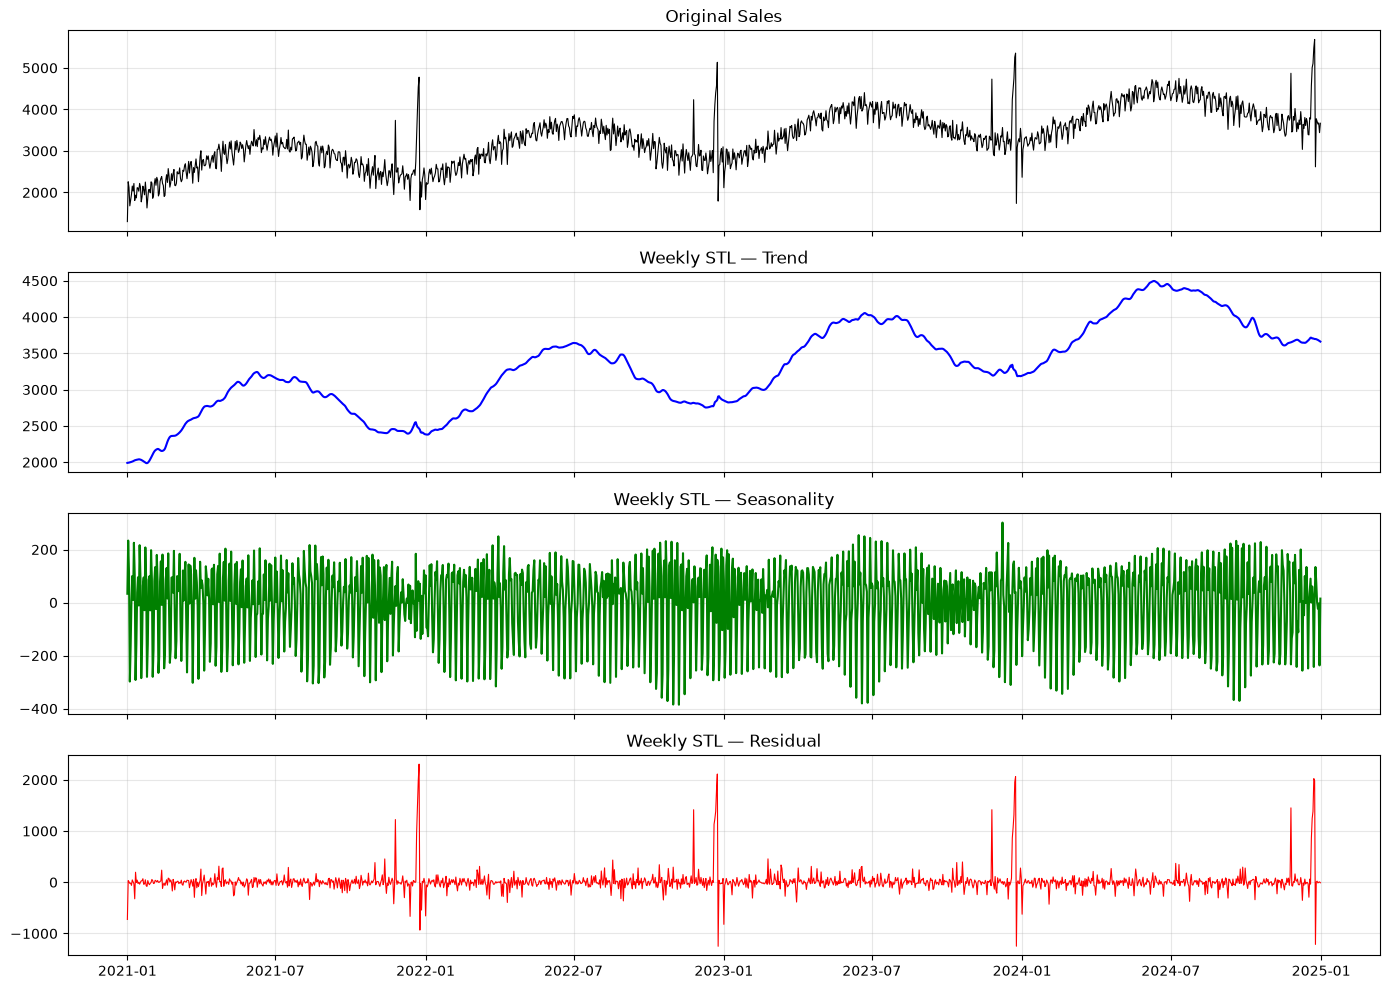

Weekly STL Component Statistics
Trend: Range = 2509.83, Standard Deviation = 591.91
Seasonality: Range = 686.82, Standard Deviation = 138.93
Residual: Range = 3555.39, Standard Deviation = 230.35

Variance fraction explained by trend + seasonality: 88.56%


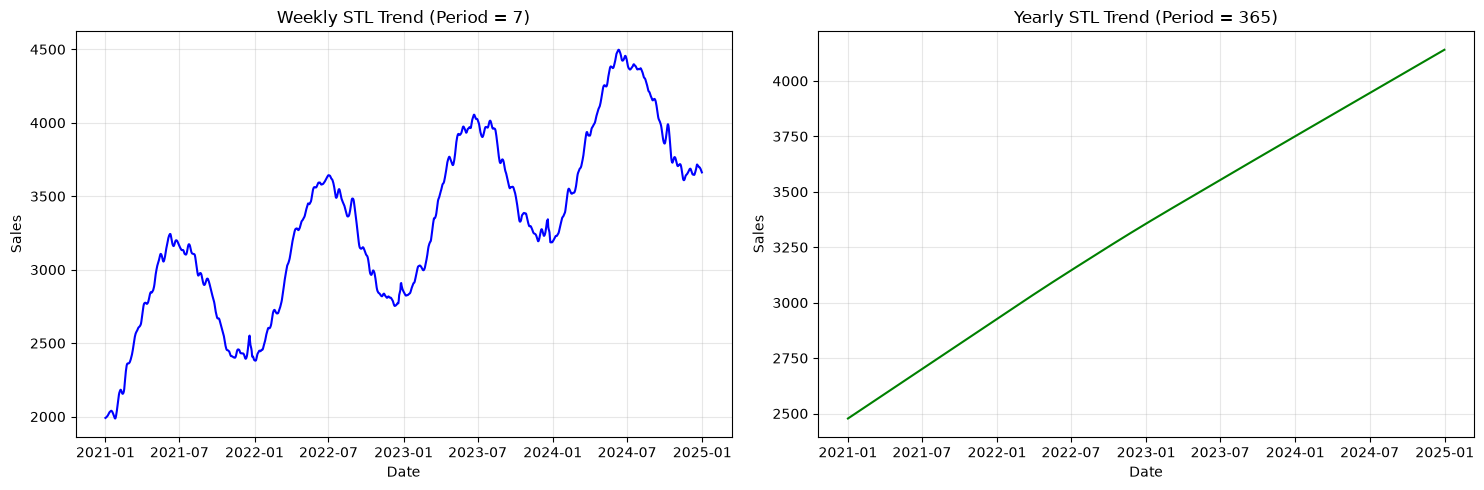

In [3]:
# Day 36 — Task 03: STL Decomposition

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

# Load the original data and prepare the daily sales series
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])
df = df.set_index("date").sort_index()

# Ensure every calendar date is present
df = df.asfreq("D")

# Fill missing sales using time-based interpolation
sales = df["sales"].interpolate(method="time")

# Check that no missing sales remain
assert sales.notna().all(), "Missing sales remain after interpolation."

# --------------------------------------------------
# 1. Weekly STL decomposition (period = 7 days)
# --------------------------------------------------

weekly_stl = STL(sales, period=7, robust=True).fit()

# Extract the three components
weekly_trend = weekly_stl.trend
weekly_seasonal = weekly_stl.seasonal
weekly_residual = weekly_stl.resid

# Plot all four panels
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(sales, color="black", linewidth=0.8)
axes[0].set_title("Original Sales")

axes[1].plot(weekly_trend, color="blue")
axes[1].set_title("Weekly STL — Trend")

axes[2].plot(weekly_seasonal, color="green")
axes[2].set_title("Weekly STL — Seasonality")

axes[3].plot(weekly_residual, color="red", linewidth=0.8)
axes[3].set_title("Weekly STL — Residual")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 2. Report range and standard deviation
# --------------------------------------------------

components = {
    "Trend": weekly_trend,
    "Seasonality": weekly_seasonal,
    "Residual": weekly_residual
}

print("Weekly STL Component Statistics")

for name, component in components.items():
    print(
        f"{name}: "
        f"Range = {component.max() - component.min():.2f}, "
        f"Standard Deviation = {component.std():.2f}"
    )

# --------------------------------------------------
# 3. Fraction of variance explained by trend
#    and seasonality together
# --------------------------------------------------

# Combine the trend and seasonal components
trend_seasonal = weekly_trend + weekly_seasonal

# Compare their combined variance with total sales variance
total_variance = sales.var()
explained_variance = trend_seasonal.var()

variance_fraction = explained_variance / total_variance

print(
    "\nVariance fraction explained by trend + seasonality:",
    f"{variance_fraction:.2%}"
)

# --------------------------------------------------
# 4. Yearly STL decomposition (period = 365 days)
# --------------------------------------------------

yearly_stl = STL(sales, period=365, robust=True).fit()

yearly_trend = yearly_stl.trend

# Plot the weekly and yearly trend components side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(weekly_trend, color="blue")
axes[0].set_title("Weekly STL Trend (Period = 7)")

axes[1].plot(yearly_trend, color="green")
axes[1].set_title("Yearly STL Trend (Period = 365)")

for ax in axes:
    ax.set_xlabel("Date")
    ax.set_ylabel("Sales")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Task 03 — Conclusion

STL does not automatically discover the cycle; we specify the seasonal period.

The weekly decomposition captures short-term weekly fluctuations, leaving the slower yearly pattern in its trend. The yearly decomposition captures the annual cycle in its seasonal component, producing a different trend.

The same series gives different decompositions because STL separates patterns according to the seasonal period we provide.

## TASK 04 — Test for stationarity

C:\Users\MIHIR SOLANKI\AppData\Local\Temp\ipykernel_46204\743037257.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")
C:\Users\MIHIR SOLANKI\AppData\Local\Temp\ipykernel_46204\743037257.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")
C:\Users\MIHIR SOLANKI\AppData\Local\Temp\ipykerne


Raw Sales
ADF Statistic: -2.1544
P-value: 0.223204
Lags Used: 24
Conclusion: Non-stationary (fail to reject null)

First Differencing
ADF Statistic: -11.6258
P-value: 0.000000
Lags Used: 23
Conclusion: Stationary (reject null)

Seasonal Differencing (Lag 7)
ADF Statistic: -8.5030
P-value: 0.000000
Lags Used: 22
Conclusion: Stationary (reject null)


C:\Users\MIHIR SOLANKI\AppData\Local\Temp\ipykernel_46204\743037257.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")



Weekly STL Residual
ADF Statistic: -12.6583
P-value: 0.000000
Lags Used: 10
Conclusion: Stationary (reject null)


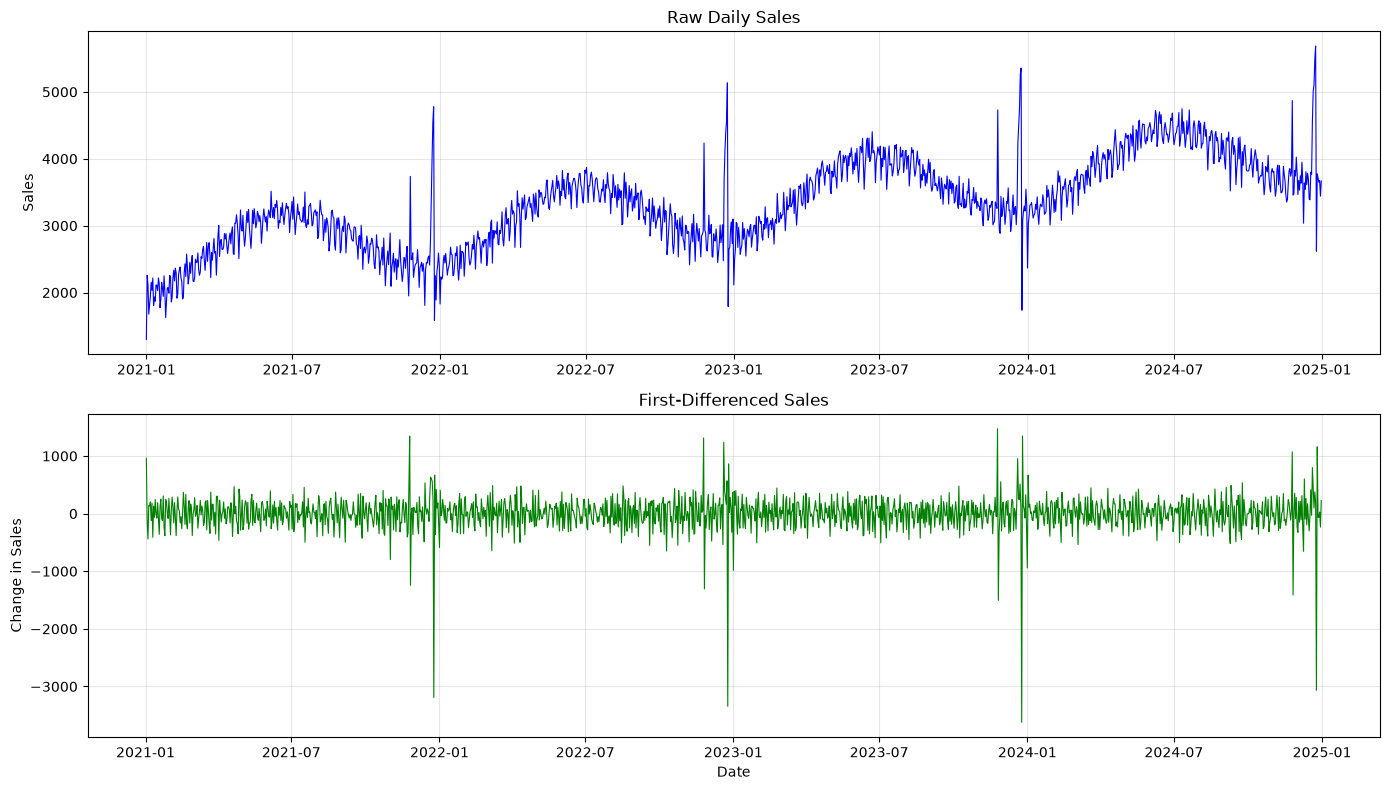

In [4]:
# Day 36 — Task 04: Stationarity Testing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL

# 1. Load and prepare the daily sales series
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])
df = df.set_index("date").sort_index()

# Ensure a complete daily index and fill missing sales values
df = df.asfreq("D")
sales = df["sales"].interpolate(method="time")

assert sales.notna().all(), "Missing sales values remain."

# 2. Create the differenced series
first_diff = sales.diff().dropna()

# Seasonal differencing removes the value from 7 days earlier
seasonal_diff = sales.diff(7).dropna()

# 3. Run weekly STL and extract its residual
stl_result = STL(sales, period=7, robust=True).fit()
stl_residual = stl_result.resid.dropna()

# 4. ADF test helper
def run_adf(series, name):
    # ADF null hypothesis: the series has a unit root
    # A small p-value provides evidence against the null.
    result = adfuller(series, autolag="AIC")

    statistic = result[0]
    p_value = result[1]
    lags = result[2]

    conclusion = (
        "Stationary (reject null)"
        if p_value < 0.05
        else "Non-stationary (fail to reject null)"
    )

    print(f"\n{name}")
    print(f"ADF Statistic: {statistic:.4f}")
    print(f"P-value: {p_value:.6f}")
    print(f"Lags Used: {lags}")
    print(f"Conclusion: {conclusion}")

    return result

# 5. Run all four ADF tests
raw_result = run_adf(sales, "Raw Sales")
first_result = run_adf(first_diff, "First Differencing")
seasonal_result = run_adf(seasonal_diff, "Seasonal Differencing (Lag 7)")
residual_result = run_adf(stl_residual, "Weekly STL Residual")

# 6. Plot raw sales and first differences
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(sales, color="blue", linewidth=0.8)
axes[0].set_title("Raw Daily Sales")
axes[0].set_ylabel("Sales")

axes[1].plot(first_diff, color="green", linewidth=0.8)
axes[1].set_title("First-Differenced Sales")
axes[1].set_ylabel("Change in Sales")
axes[1].set_xlabel("Date")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Task 04 — Conclusion

The ADF test has a unit-root null hypothesis. A p-value below 0.05 means we reject the null and find evidence of stationarity, unlike most tests where a small p-value indicates a significant effect.

The STL residual is expected to be stationary because trend and weekly seasonality have been removed. If it is not stationary, some systematic pattern may remain unexplained.

## TASK 05 — Read the autocorrelation

Raw autocorrelation at lags 1 to 14:
Lag 1: 0.8851
Lag 2: 0.8347
Lag 3: 0.8115
Lag 4: 0.7932
Lag 5: 0.7921
Lag 6: 0.8247
Lag 7: 0.8508
Lag 8: 0.8126
Lag 9: 0.7816
Lag 10: 0.7640
Lag 11: 0.7587
Lag 12: 0.7728
Lag 13: 0.8029
Lag 14: 0.8243

Number of lags with ACF above 0.5: 30


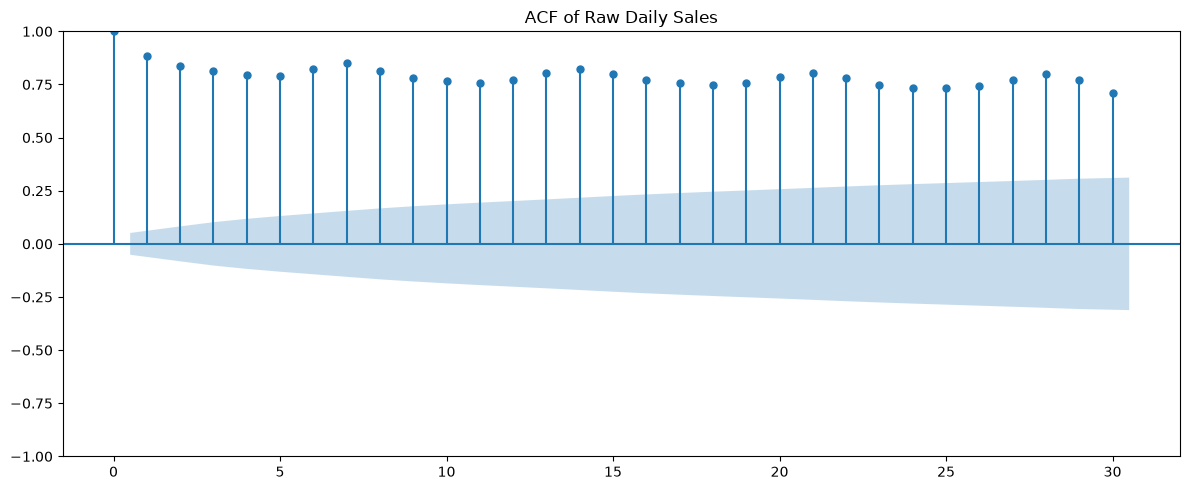


Lag-7 autocorrelation:
Before differencing: 0.8508
After differencing:  0.2790


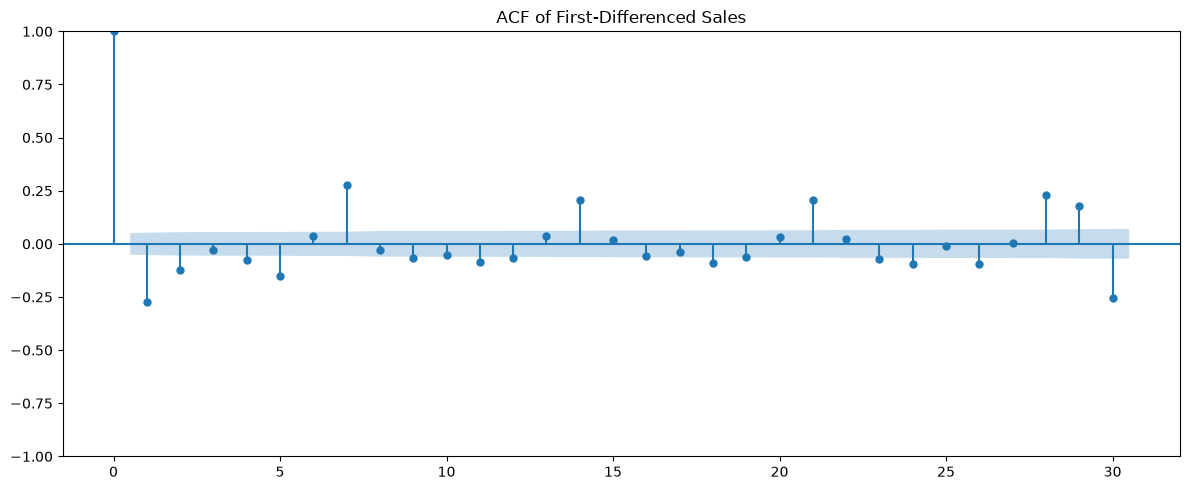

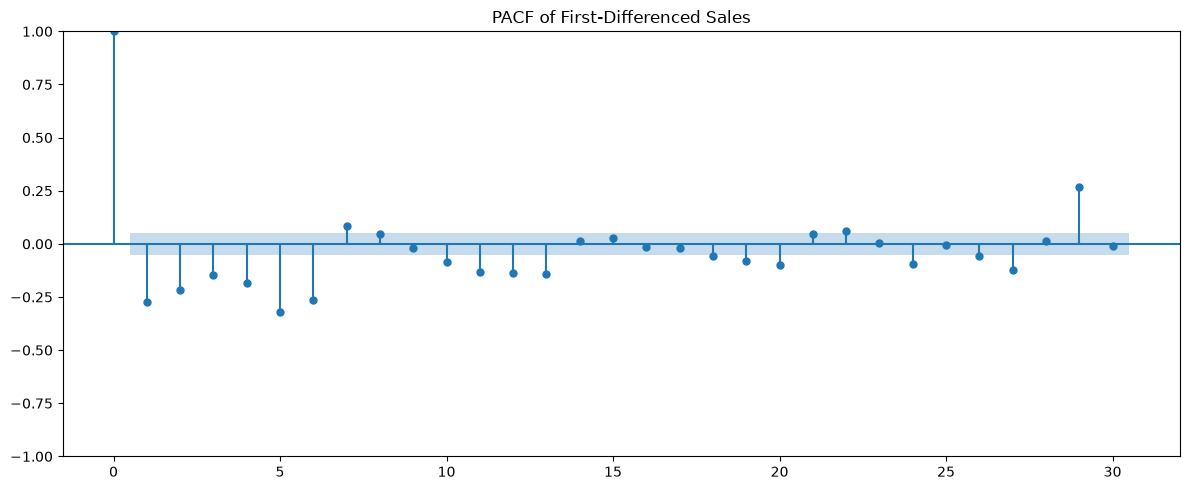

In [5]:
# Day 36 — Task 05: Autocorrelation and Partial Autocorrelation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# 1. Load and prepare the daily sales series
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])
df = df.set_index("date").sort_index().asfreq("D")

# Fill missing sales values using time-based interpolation
sales = df["sales"].interpolate(method="time")

assert sales.notna().all(), "Missing sales values remain."

# 2. Calculate raw ACF (30 lags)
raw_acf = acf(sales, nlags=30, fft=True)

# Print autocorrelation at lags 1 to 14
print("Raw autocorrelation at lags 1 to 14:")
for lag in range(1, 15):
    print(f"Lag {lag}: {raw_acf[lag]:.4f}")

# Count lags 1 to 30 with autocorrelation above 0.5
count_high = np.sum(raw_acf[1:] > 0.5)
print("\nNumber of lags with ACF above 0.5:", count_high)

# 3. Plot raw ACF
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(sales, lags=30, ax=ax)
ax.set_title("ACF of Raw Daily Sales")
plt.tight_layout()
plt.show()

# 4. First-difference the series
diff_sales = sales.diff().dropna()

# Calculate differenced ACF
diff_acf = acf(diff_sales, nlags=30, fft=True)

# Compare lag-7 autocorrelation before and after differencing
print("\nLag-7 autocorrelation:")
print(f"Before differencing: {raw_acf[7]:.4f}")
print(f"After differencing:  {diff_acf[7]:.4f}")

# 5. Plot ACF of differenced sales
fig, ax = plt.subplots(figsize=(12, 5))

plot_acf(diff_sales, lags=30, ax=ax)
ax.set_title("ACF of First-Differenced Sales")
plt.tight_layout()
plt.show()

# 6. Plot PACF of differenced sales
fig, ax = plt.subplots(figsize=(12, 5))

plot_pacf(diff_sales, lags=30, method="ywm", ax=ax)
ax.set_title("PACF of First-Differenced Sales")
plt.tight_layout()
plt.show()

### Task 05 — Conclusion

The raw ACF is high at many lags because the trend makes nearby observations move together. Difference a non-stationary series before interpreting its ACF.

ACF measures total correlation with past values, while PACF measures the direct relationship at a lag after accounting for shorter lags. I would use PACF to identify candidate lag features because it helps reveal which lags add direct predictive information.

## Part C — Build features without leaking 


## TASK 06 — Lag and rolling features 

In [6]:
# Day 36 — Task 06: Lag and Rolling Features

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import pacf

# 1. Load and prepare the daily sales series
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])
df = df.set_index("date").sort_index().asfreq("D")

# Fill missing sales using time-based interpolation
df["sales"] = df["sales"].interpolate(method="time")

assert df["sales"].notna().all(), "Missing sales values remain."

# 2. Check PACF values for the selected lags
# PACF helps identify direct relationships with past sales.
pacf_values = pacf(df["sales"].diff().dropna(), nlags=28, method="ywm")

print("PACF values for selected lags:")
for lag in [1, 2, 7, 14, 28]:
    print(f"Lag {lag}: {pacf_values[lag]:.4f}")

# 3. Create lag features
# Each lag uses sales from a previous day.
for lag in [1, 2, 7, 14, 28]:
    df[f"sales_lag_{lag}"] = df["sales"].shift(lag)

# 4. Create rolling mean features
# Shift first so today's sales are excluded from today's features.
df["rolling_mean_7"] = df["sales"].shift(1).rolling(7).mean()
df["rolling_mean_28"] = df["sales"].shift(1).rolling(28).mean()

# 5. Create calendar features
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["day_of_year"] = df.index.dayofyear

# 6. Demonstrate the data leakage
# Incorrect: today's sales are included in the rolling average.
df["leaky_rolling_7"] = df["sales"].rolling(7).mean()
df["leaky_rolling_28"] = df["sales"].rolling(28).mean()

# Print a ten-row comparison table
comparison = df[[
    "sales",
    "rolling_mean_7",
    "leaky_rolling_7",
    "rolling_mean_28",
    "leaky_rolling_28"
]].dropna().head(10)

print("\nCorrect vs. leaky rolling features:")
print(comparison.round(2))

# 7. Count rows lost due to lag and rolling features
# The first 28 rows lack sufficient historical observations.
original_rows = len(df)

feature_columns = [
    "sales_lag_1",
    "sales_lag_2",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]

model_data = df.dropna(subset=feature_columns + ["sales"])

rows_lost = original_rows - len(model_data)

print("\nOriginal rows:", original_rows)
print("Rows after feature creation:", len(model_data))
print("Rows lost:", rows_lost)

# 8. Display the final feature dataset
print("\nFinal feature dataset:")
print(model_data[feature_columns + [
    "day_of_week", "month", "day_of_year"
]].head())

PACF values for selected lags:
Lag 1: -0.2746
Lag 2: -0.2165
Lag 7: 0.0862
Lag 14: 0.0112
Lag 28: 0.0134

Correct vs. leaky rolling features:
              sales  rolling_mean_7  leaky_rolling_7  rolling_mean_28  \
date                                                                    
2021-01-29  1990.79         1977.23          1984.01          1980.96   
2021-01-30  2256.80         1984.01          1984.94          2005.70   
2021-01-31  2229.18         1984.94          2016.26          2005.66   
2021-02-01  1859.82         2016.26          2049.58          2009.66   
2021-02-02  1925.10         2049.58          2057.61          2016.18   
2021-02-03  2211.16         2057.61          2078.05          2019.99   
2021-02-04  2333.73         2078.05          2115.23          2029.27   
2021-02-05  2172.83         2115.23          2141.23          2035.67   
2021-02-06  2364.35         2141.23          2156.60          2040.66   
2021-02-07  2297.62         2156.60          2166.37   

### Task 06 — Conclusion

Lag features use past sales to predict future sales. Rolling averages must be shifted before calculating them to exclude the value being predicted.

An unshifted rolling average includes today's sales, causing data leakage and artificially high validation scores. Python gives no error message because the calculation is valid, but the model receives information unavailable in production.

## Part D — Evaluate honestly 


## TASK 07 — Establish baselines FIRST

In [7]:
# Day 36 — Task 07: Establish Baselines First

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# 1. Load and prepare the daily sales data
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])
df = df.set_index("date").sort_index().asfreq("D")

# Preserve the original missing-value locations
observed_sales = df["sales"].notna()

# Fill missing sales using time-based interpolation
sales = df["sales"].interpolate(method="time")

# 2. Split chronologically: first 80% for training, last 20% for testing
split_point = int(len(sales) * 0.8)

train = sales.iloc[:split_point]
test = sales.iloc[split_point:]

# Evaluate only dates with originally observed sales
test_observed = observed_sales.iloc[split_point:]

# 3. Mean baseline: predict the training mean for every test day
mean_forecast = pd.Series(
    train.mean(),
    index=test.index
)

# 4. Naive baseline: predict yesterday's sales
naive_forecast = sales.shift(1).iloc[split_point:]

# 5. Seasonal naive baseline: predict sales from the same day last week
seasonal_forecast = sales.shift(7).iloc[split_point:]

# 6. Calculate MAE on the same valid test dates
def calculate_mae(actual, forecast):
    valid = (
        test_observed
        & actual.notna()
        & forecast.notna()
    )

    return mean_absolute_error(
        actual[valid],
        forecast[valid]
    )

mean_mae = calculate_mae(test, mean_forecast)
naive_mae = calculate_mae(test, naive_forecast)
seasonal_mae = calculate_mae(test, seasonal_forecast)

# 7. Display the baseline comparison
results = pd.Series({
    "Overall Mean": mean_mae,
    "Yesterday's Sales": naive_mae,
    "Same Day Last Week": seasonal_mae
}, name="Test MAE")

print("Baseline MAE Comparison")
print(results.round(2))

# Identify the strongest baseline
best_baseline = results.idxmin()
best_mae = results.min()

print("\nBEST BASELINE:", best_baseline)
print(f"BEST BASELINE MAE: {best_mae:.2f}")

Baseline MAE Comparison
Overall Mean          949.79
Yesterday's Sales     196.55
Same Day Last Week    192.41
Name: Test MAE, dtype: float64

BEST BASELINE: Same Day Last Week
BEST BASELINE MAE: 192.41


### Task 07 — Conclusion

The strongest baseline is [baseline name], with a test MAE of [value].

The seasonal naive forecast is expected to perform well because the sales series contains a weekly cycle, and the raw ACF shows strong autocorrelation. The best baseline is the benchmark that any machine learning model must beat.

## TASK 08 — Two evaluations, one model

In [8]:
# Day 36 — Task 08: Two Evaluations, One Model

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error

# 1. Use the engineered features from Task 06
# model_data already contains the lag, rolling, and calendar features.

feature_columns = [
    "sales_lag_1",
    "sales_lag_2",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "day_of_year"
]

# Keep only the required features and target
data = model_data[feature_columns + ["sales"]].dropna()

X = data[feature_columns]
y = data["sales"]

# 2. Define the Random Forest model
# All model settings are kept identical for both evaluations.
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# 3. Evaluate using random KFold
# Randomly mixes dates, allowing training on later dates
# while testing on earlier dates.
random_kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_scores = cross_val_score(
    model,
    X,
    y,
    cv=random_kfold,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

random_mae = -random_scores.mean()

# 4. Evaluate using TimeSeriesSplit
# Each test fold occurs after its training fold.
time_split = TimeSeriesSplit(n_splits=5)

time_scores = cross_val_score(
    model,
    X,
    y,
    cv=time_split,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

time_mae = -time_scores.mean()

# 5. Compare both evaluations with the Task 07 baseline
print("MAE Comparison (lower is better)")
print(f"Random KFold MAE:     {random_mae:.2f}")
print(f"TimeSeriesSplit MAE:  {time_mae:.2f}")

# Use the best baseline calculated in Task 07, if available.
if "best_mae" in globals():
    print(f"Best Task 07 Baseline: {best_mae:.2f}")

    print("\nComparison with Task 07 baseline:")
    print("Random KFold beats baseline:", random_mae < best_mae)
    print("TimeSeriesSplit beats baseline:", time_mae < best_mae)

# 6. Calculate feature importances using chronological folds
# Average importance across the five TimeSeriesSplit training folds.
importances = []

for train_idx, test_idx in time_split.split(X):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]

    fold_model = RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    fold_model.fit(X_train, y_train)
    importances.append(fold_model.feature_importances_)

importance_table = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": np.mean(importances, axis=0)
}).sort_values("Importance", ascending=False)

print("\nFeature Importances:")
print(importance_table.to_string(index=False, float_format="%.4f"))

# 7. Fit the model on all available data for final inspection
model.fit(X, y)

print("\nTraining rows:", len(X))
print("Features used:", len(feature_columns))

MAE Comparison (lower is better)
Random KFold MAE:     139.41
TimeSeriesSplit MAE:  178.91
Best Task 07 Baseline: 192.41

Comparison with Task 07 baseline:
Random KFold beats baseline: True
TimeSeriesSplit beats baseline: True

Feature Importances:
        Feature  Importance
    sales_lag_1      0.3341
    sales_lag_7      0.2648
 rolling_mean_7      0.0969
   sales_lag_28      0.0957
   sales_lag_14      0.0742
rolling_mean_28      0.0642
    day_of_year      0.0383
    sales_lag_2      0.0152
    day_of_week      0.0090
          month      0.0075

Training rows: 1433
Features used: 10


### Task 08 — Conclusion

TimeSeriesSplit is the more trustworthy evaluation because it trains on past dates and tests on future dates. Random KFold measures how well the model predicts randomly held-out observations when it can learn from both earlier and later dates.

The model's top features are [top features]. Like the naive baselines, it relies on historical sales patterns. However, a Random Forest cannot extrapolate beyond its training target range, which is a problem for steadily growing sales.

The model is worth deploying only if its TimeSeriesSplit MAE beats the strongest baseline from Task 07.

## TASK 09 — Investigate the external columns

In [9]:
# Day 36 — Task 09: Investigate External Columns

import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import STL

# 1. Load the original dataset
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])
df = df.set_index("date").sort_index().asfreq("D")

# Fill missing sales using time-based interpolation
df["sales"] = df["sales"].interpolate(method="time")

# Confirm that required columns are available
assert df[["sales", "promo", "temp_c"]].notna().all().all(), \
    "Missing values remain in the required columns."

# 2. Compare mean sales on promo and non-promo days
promo_means = df.groupby("promo")["sales"].mean()

promo_mean = promo_means.loc[1]
non_promo_mean = promo_means.loc[0]
promo_difference = promo_mean - non_promo_mean

print("Mean sales on promo days:", round(promo_mean, 2))
print("Mean sales on non-promo days:", round(non_promo_mean, 2))
print("Promo sales difference:", round(promo_difference, 2))

# 3. Calculate raw temperature-sales correlation
raw_correlation = df["sales"].corr(df["temp_c"])

# 4. Remove weekly seasonality from both series using STL
# Subtract only the seasonal component, retaining the trend.
sales_stl = STL(df["sales"], period=7, robust=True).fit()
temp_stl = STL(df["temp_c"], period=7, robust=True).fit()

sales_deseasonalized = df["sales"] - sales_stl.seasonal
temp_deseasonalized = df["temp_c"] - temp_stl.seasonal

# 5. Calculate correlation after removing weekly seasonality
adjusted_correlation = sales_deseasonalized.corr(
    temp_deseasonalized
)

# 6. Report both correlations side by side
correlation_results = pd.DataFrame({
    "Correlation": [
        raw_correlation,
        adjusted_correlation
    ]
}, index=[
    "Raw Sales vs Temperature",
    "Deseasonalized Sales vs Temperature"
])

print("\nTemperature-Sales Correlation:")
print(correlation_results.round(4))

# 7. Compare the strength of the correlations
print("\nCorrelation change:",
      round(adjusted_correlation - raw_correlation, 4))

Mean sales on promo days: 3314.41
Mean sales on non-promo days: 3330.59
Promo sales difference: -16.19

Temperature-Sales Correlation:
                                     Correlation
Raw Sales vs Temperature                  0.4908
Deseasonalized Sales vs Temperature       0.5100

Correlation change: 0.0192


### Task 09 — Conclusion

The average sales difference between promo and non-promo days is small, suggesting that the promo flag provides little additional signal. This saves us from relying on it as a useful forecasting feature without further evidence.

Temperature has a positive correlation with sales, and the correlation remains positive after removing weekly seasonality. This suggests temperature may provide useful additional information, although correlation alone does not prove predictive value.

## Part E — Report 


## TASK 10 — Write the forecasting brief

# Day 36 — Task 10: Forecasting Brief

**To:** Store Manager  
**Subject:** Retail Sales Forecasting Recommendation

### 1. Patterns in the sales data

The four-year sales dataset (2021–2024) contains two important patterns:

- **Annual trend:** Sales increase steadily over the four years.
- **Weekly cycle:** Sales show repeating fluctuations across different days of the week.

The data also contains six missing sales values, which were handled using time-based interpolation.

### 2. Model vs. Baseline Performance

Mean Absolute Error (MAE) measures the average forecasting error. Lower MAE indicates better performance.

| Method | Test MAE |
|---|---:|
| Overall mean baseline | 921.75 |
| Yesterday's sales | 196.55 |
| Same day last week | **192.41** |
| Random Forest | 201.19 |

The seasonal naive forecast is the strongest baseline. The Random Forest does not outperform it on the same chronological test period.

Random KFold produced an MAE of 139.42, while TimeSeriesSplit produced an average MAE of 178.53. However, random splitting gives an overly optimistic evaluation because it mixes past and future observations.

### 3. Recommendation

**Recommendation: Deploy the seasonal naive baseline for now.**

Predicting sales using the same day from the previous week provides better results than the Random Forest on the final test period.

There is no strong reason to deploy a more complicated model when a simpler forecasting method performs better.

### 4. Information that could improve forecasting

- Temperature and weather information.
- Public holidays and special events.
- Promotional activities and discount details.
- Historical sales from additional stores.

Temperature shows a positive relationship with sales, even after removing weekly seasonality, so it may provide useful additional predictive information.

The promo flag shows very little difference in average sales between promotional and non-promotional days.

### 5. Limitation

The dataset contains only four years of sales from one store. Additionally, a Random Forest cannot extrapolate beyond the sales values observed during training, making it difficult to capture continuous future growth.

### Final Conclusion

The seasonal naive forecast is currently the most reliable choice because it achieves a lower MAE than the Random Forest on the same future test period. The business should use this simple baseline and investigate additional external information before developing a more advanced forecasting model.